# Estudo Analítico e Preditivo de Partidas de Xadrez

Este notebook contém uma análise exploratória para responder a perguntas frequentes sobre partidas de xadrez (desistências, mates, empates e tipo de partida) e a construção/avaliação de modelos de Machine Learning (**Árvore de Decisão**, **Naive Bayes** e **Regressão Logística**) para prever o vencedor da partida.

In [2]:
import pandas as pd 

df = pd.read_csv('./dados/chess_games.csv')

df.head()

,game_id,rated,turns,victory_status,winner,time_increment,white_id,white_rating,black_id,black_rating,moves,opening_code,opening_moves,opening_fullname,opening_shortname,opening_response,opening_variation
0,1,False,13,Out of Time,White,15+2,bourgris,1500,a-00,1191,d4 d5 c4 c6 cxd5 e6 dxe6 fxe6 Nf3 Bb4+ Nc3 Ba5...,D10,5,Slav Defense: Exchange Variation,Slav Defense,NaN,Exchange Variation
1,2,True,16,Resign,Black,5+10,a-00,1322,skinnerua,1261,d4 Nc6 e4 e5 f4 f6 dxe5 fxe5 fxe5 Nxe5 Qd4 Nc6...,B00,4,Nimzowitsch Defense: Kennedy Variation,Nimzowitsch Defense,NaN,Kennedy Variation
2,3,True,61,Mate,White,5+10,ischia,1496,a-00,1500,e4 e5 d3 d6 Be3 c6 Be2 b5 Nd2 a5 a4 c5 axb5 Nc...,C20,3,King's Pawn Game: Leonardis Variation,King's Pawn Game,NaN,Leonardis Variation
3,4,True,61,Mate,White,20+0,daniamurashov,1439,adivanov2009,1454,d4 d5 Nf3 Bf5 Nc3 Nf6 Bf4 Ng4 e3 Nc6 Be2 Qd7 O...,D02,3,Queen's Pawn Game: Zukertort Variation,Queen's Pawn Game,NaN,Zukertort Variation
4,5,True,95,Mate,White,30+3,nik221107,1523,adivanov2009,1469,e4 e5 Nf3 d6 d4 Nc6 d5 Nb4 a3 Na6 Nc3 Be7 b4 N...,C41,5,Philidor Defense,Philidor Defense,NaN,NaN


In [3]:
df["winner"]

0        White
1        Black
2        White
3        White
4        White
         ...  
20053    White
20054    Black
20055    White
20056    White
20057    Black
Name: winner, Length: 20058, dtype: object

# Verificação das respostas pelo dummy

In [4]:
exemplo_dummy = pd.get_dummies(df["winner"])
exemplo_dummy

,Black,Draw,White
0,False,False,True
1,True,False,False
2,False,False,True
3,False,False,True
4,False,False,True
...,...,...,...
20053,False,False,True
20054,True,False,False
20055,False,False,True
20056,False,False,True


In [5]:
exemplo_dummy = pd.get_dummies(df["winner"]).astype(int)
exemplo_dummy

,Black,Draw,White
0,0,0,1
1,1,0,0
2,0,0,1
3,0,0,1
4,0,0,1
...,...,...,...
20053,0,0,1
20054,1,0,0
20055,0,0,1
20056,0,0,1


In [6]:
exemplo_tempo = pd.get_dummies(df["time_increment"])
exemplo_tempo

,0+12,0+13,0+15,0+16,0+180,0+20,0+25,0+30,0+40,1+10,...,9+5,9+6,9+7,9+8,9+9,90+0,90+120,90+30,90+5,90+8
0,False,False,False,False,False,False,False,False,False,False,...,False,False,False,False,False,False,False,False,False,False
1,False,False,False,False,False,False,False,False,False,False,...,False,False,False,False,False,False,False,False,False,False
2,False,False,False,False,False,False,False,False,False,False,...,False,False,False,False,False,False,False,False,False,False
3,False,False,False,False,False,False,False,False,False,False,...,False,False,False,False,False,False,False,False,False,False
4,False,False,False,False,False,False,False,False,False,False,...,False,False,False,False,False,False,False,False,False,False
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
20053,False,False,False,False,False,False,False,False,False,False,...,False,False,False,False,False,False,False,False,False,False
20054,False,False,False,False,False,False,False,False,False,False,...,False,False,False,False,False,False,False,False,False,False
20055,False,False,False,False,False,False,False,False,False,False,...,False,False,False,False,False,False,False,False,False,False
20056,False,False,False,False,False,False,False,False,False,False,...,False,False,False,False,False,False,False,False,False,False


In [7]:
exemplo_op_code = pd.get_dummies(df["opening_code"])
exemplo_op_code

,A00,A01,A02,A03,A04,A05,A06,A07,A08,A09,...,E81,E87,E88,E90,E91,E92,E94,E95,E97,E98
0,False,False,False,False,False,False,False,False,False,False,...,False,False,False,False,False,False,False,False,False,False
1,False,False,False,False,False,False,False,False,False,False,...,False,False,False,False,False,False,False,False,False,False
2,False,False,False,False,False,False,False,False,False,False,...,False,False,False,False,False,False,False,False,False,False
3,False,False,False,False,False,False,False,False,False,False,...,False,False,False,False,False,False,False,False,False,False
4,False,False,False,False,False,False,False,False,False,False,...,False,False,False,False,False,False,False,False,False,False
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
20053,False,False,False,False,False,False,False,False,False,False,...,False,False,False,False,False,False,False,False,False,False
20054,False,False,False,False,False,False,False,False,False,False,...,False,False,False,False,False,False,False,False,False,False
20055,False,False,False,False,False,False,False,False,False,False,...,False,False,False,False,False,False,False,False,False,False
20056,False,False,False,False,False,False,False,False,False,False,...,False,False,False,False,False,False,False,False,False,False


In [8]:
exemplo_op_moves = pd.get_dummies(df['opening_moves'])
exemplo_op_moves

,1,2,3,4,5,6,7,8,9,10,...,14,15,16,17,18,19,20,22,24,28
0,False,False,False,False,True,False,False,False,False,False,...,False,False,False,False,False,False,False,False,False,False
1,False,False,False,True,False,False,False,False,False,False,...,False,False,False,False,False,False,False,False,False,False
2,False,False,True,False,False,False,False,False,False,False,...,False,False,False,False,False,False,False,False,False,False
3,False,False,True,False,False,False,False,False,False,False,...,False,False,False,False,False,False,False,False,False,False
4,False,False,False,False,True,False,False,False,False,False,...,False,False,False,False,False,False,False,False,False,False
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
20053,False,True,False,False,False,False,False,False,False,False,...,False,False,False,False,False,False,False,False,False,False
20054,False,True,False,False,False,False,False,False,False,False,...,False,False,False,False,False,False,False,False,False,False
20055,False,False,True,False,False,False,False,False,False,False,...,False,False,False,False,False,False,False,False,False,False
20056,False,False,False,True,False,False,False,False,False,False,...,False,False,False,False,False,False,False,False,False,False


In [10]:
exemplo_op_fullname = pd.get_dummies(df["opening_fullname"])
exemplo_op_fullname

,Alekhine Defense,Alekhine Defense #2,Alekhine Defense #3,Alekhine Defense: Balogh Variation,Alekhine Defense: Brooklyn Variation,Alekhine Defense: Exchange Variation,Alekhine Defense: Four Pawns Attack,Alekhine Defense: Four Pawns Attack | 6...Nc6,Alekhine Defense: Four Pawns Attack | Fianchetto Variation,Alekhine Defense: Four Pawns Attack | Main Line,...,Zukertort Opening: Quiet System,Zukertort Opening: Reversed Mexican Defense,Zukertort Opening: Ross Gambit,Zukertort Opening: Santasiere's Folly,Zukertort Opening: Sicilian Invitation,Zukertort Opening: Slav Invitation,Zukertort Opening: Tennison Gambit,Zukertort Opening: The Walrus,Zukertort Opening: Vos Gambit,Zukertort Opening: Wade Defense
0,False,False,False,False,False,False,False,False,False,False,...,False,False,False,False,False,False,False,False,False,False
1,False,False,False,False,False,False,False,False,False,False,...,False,False,False,False,False,False,False,False,False,False
2,False,False,False,False,False,False,False,False,False,False,...,False,False,False,False,False,False,False,False,False,False
3,False,False,False,False,False,False,False,False,False,False,...,False,False,False,False,False,False,False,False,False,False
4,False,False,False,False,False,False,False,False,False,False,...,False,False,False,False,False,False,False,False,False,False
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
20053,False,False,False,False,False,False,False,False,False,False,...,False,False,False,False,False,False,False,False,False,False
20054,False,False,False,False,False,False,False,False,False,False,...,False,False,False,False,False,False,False,False,False,False
20055,False,False,False,False,False,False,False,False,False,False,...,False,False,False,False,False,False,False,False,False,False
20056,False,False,False,False,False,False,False,False,False,False,...,False,False,False,False,False,False,False,False,False,False


In [11]:
exemplo_op_shortname = pd.get_dummies(df['opening_shortname'])
exemplo_op_shortname

,Alekhine Defense,Amar Opening,Amazon Attack,Anderssen Opening,Australian Defense,Barnes Defense,Barnes Opening,Benko Gambit,Benoni Defense,Bird Opening,...,Trompowsky Attack,Valencia Opening,Van Geet Opening,Van't Kruijs Opening,Vienna Game,Wade Defense,Ware Defense,Ware Opening,Yusupov-Rubinstein System,Zukertort Opening
0,False,False,False,False,False,False,False,False,False,False,...,False,False,False,False,False,False,False,False,False,False
1,False,False,False,False,False,False,False,False,False,False,...,False,False,False,False,False,False,False,False,False,False
2,False,False,False,False,False,False,False,False,False,False,...,False,False,False,False,False,False,False,False,False,False
3,False,False,False,False,False,False,False,False,False,False,...,False,False,False,False,False,False,False,False,False,False
4,False,False,False,False,False,False,False,False,False,False,...,False,False,False,False,False,False,False,False,False,False
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
20053,False,False,False,False,False,False,False,False,False,False,...,False,False,False,False,False,False,False,False,False,False
20054,False,False,False,False,False,False,False,False,False,False,...,False,False,False,False,False,False,False,False,False,False
20055,False,False,False,False,False,False,False,False,False,False,...,False,False,False,False,False,False,False,False,False,False
20056,False,False,False,False,False,False,False,False,False,False,...,False,False,False,False,False,False,False,False,False,False


In [12]:
exemplo_op_response = pd.get_dummies(df['opening_response'])
exemplo_op_response

,Accepted,Declined,Refused
0,False,False,False
1,False,False,False
2,False,False,False
3,False,False,False
4,False,False,False
...,...,...,...
20053,False,False,False
20054,False,False,False
20055,False,False,False
20056,False,False,False


In [13]:
exemplo_op_variation = pd.get_dummies(df['opening_variation'])
exemplo_op_variation

,#2,#3,#4,#5,2.b3,3.Nc3,4.Bg5 Be7,4.e3 e8g8,Accelerated Averbakh Variation,Accelerated Dragon,...,Zeller Defense,Zhuravlev Countergambit #2,Zilbermints Gambit,Zinnowitz Variation,Zukertort System,Zukertort Variation,Zurich Gambit,von Hennig Gambit,von Popiel Gambit,von der Lasa Gambit
0,False,False,False,False,False,False,False,False,False,False,...,False,False,False,False,False,False,False,False,False,False
1,False,False,False,False,False,False,False,False,False,False,...,False,False,False,False,False,False,False,False,False,False
2,False,False,False,False,False,False,False,False,False,False,...,False,False,False,False,False,False,False,False,False,False
3,False,False,False,False,False,False,False,False,False,False,...,False,False,False,False,False,True,False,False,False,False
4,False,False,False,False,False,False,False,False,False,False,...,False,False,False,False,False,False,False,False,False,False
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
20053,False,False,False,False,False,False,False,False,False,False,...,False,False,False,False,False,False,False,False,False,False
20054,False,False,False,False,False,False,False,False,False,False,...,False,False,False,False,False,False,False,False,False,False
20055,False,False,False,False,False,False,False,False,False,False,...,False,False,False,False,False,False,False,False,False,False
20056,False,False,False,False,False,False,False,False,False,False,...,False,False,False,False,False,False,False,False,False,False


## 1. Análise Exploratória e Perguntas de Negócio

In [14]:
# 1. Quem ganhou mais em partidas avaliadas (rated) ou não avaliadas?
print("--- Vitória por tipo de partida (rated) ---")
print(pd.crosstab(df['rated'], df['winner']))

--- Vitória por tipo de partida (rated) ---
winner  Black  Draw  White
rated                     
False    1723   231   1949
True     7384   719   8052


In [15]:
# 2. Quanto tempo para o jogador desistir?
resign_games = df[df['victory_status'] == 'Resign']
print("--- Estatísticas de turnos até a desistência ---")
print(resign_games['turns'].describe())

--- Estatísticas de turnos até a desistência ---
count    11147.000000
mean        53.912533
std         29.665326
min          1.000000
25%         33.000000
50%         50.000000
75%         70.000000
max        218.000000
Name: turns, dtype: float64


In [16]:
# 3. Quem desiste mais (brancas ou pretas)?
# Nota: Se as Brancas venceram por Resign, significa que as Pretas desistiram (e vice-versa).
print("--- Vencedor nas partidas encerradas por desistência ---")
print(df[df['victory_status'] == 'Resign']['winner'].value_counts())

--- Vencedor nas partidas encerradas por desistência ---
winner
White    5844
Black    5303
Name: count, dtype: int64


In [17]:
# 4. Quanto tempo para o mate?
mate_games = df[df['victory_status'] == 'Mate']
print("--- Estatísticas de turnos até o Xeque-Mate ---")
print(mate_games['turns'].describe())

--- Estatísticas de turnos até o Xeque-Mate ---
count    6325.000000
mean       65.415020
std        33.245468
min         4.000000
25%        42.000000
50%        59.000000
75%        82.000000
max       222.000000
Name: turns, dtype: float64


## 2. Engenharia de Atributos e Dummies
Transformação de variáveis categóricas em variáveis binárias (Dummies) para modelagem.

In [18]:
from sklearn.preprocessing import StandardScaler
from sklearn.model_selection import train_test_split

# Filtrando apenas jogos decisivos (White ou Black) para classificação binária
df_model = df[df['winner'].isin(['White', 'Black'])].copy()
df_model['target'] = (df_model['winner'] == 'White').astype(int)

# Criando a diferença de rating entre os jogadores
df_model['rating_diff'] = df_model['white_rating'] - df_model['black_rating']
num_cols = ['turns', 'white_rating', 'black_rating', 'rating_diff']

# Variáveis Dummies para colunas categóricas chave
dummy_status = pd.get_dummies(df_model['victory_status'], prefix='status').astype(int)
dummy_shortname = pd.get_dummies(df_model['opening_shortname'], prefix='opening').astype(int)

# Concatenando features e criando X e y
X = pd.concat([df_model[num_cols], dummy_status, dummy_shortname], axis=1)
y = df_model['target']

# Normalizando as variáveis preditoras
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

# Divisão dos dados em treino (70%) e teste (30%)
X_train, X_test, y_train, y_test = train_test_split(X_scaled, y, test_size=0.3, random_state=42)

## 3. Treinamento e Avaliação de Modelos
Treinando a **Árvore de Decisão**, **Naive Bayes** e **Regressão Logística**, avaliando por Acurácia, Precisão, Recall, AUC e Matriz de Confusão.

In [19]:
from sklearn import tree, naive_bayes, linear_model, metrics

models = {
    "Árvore de Decisão": tree.DecisionTreeClassifier(random_state=42, min_samples_leaf=10),
    "Naive Bayes": naive_bayes.GaussianNB(),
    "Regressão Logística": linear_model.LogisticRegression(max_iter=2000, random_state=42)
}

results = {}

for name, model in models.items():
    model.fit(X_train, y_train)
    pred = model.predict(X_test)
    proba = model.predict_proba(X_test)[:, 1]
    
    acc = metrics.accuracy_score(y_test, pred)
    prec = metrics.precision_score(y_test, pred)
    rec = metrics.recall_score(y_test, pred)
    auc = metrics.roc_auc_score(y_test, proba)
    cm = metrics.confusion_matrix(y_test, pred)
    fpr, tpr, _ = metrics.roc_curve(y_test, proba)
    
    results[name] = {"acc": acc, "prec": prec, "rec": rec, "auc": auc, "cm": cm, "fpr": fpr, "tpr": tpr}
    
    print("=" * 40)
    print(f"Modelo: {name}")
    print("=" * 40)
    print(f"• Acurácia : {acc:.4f}")
    print(f"• Precisão : {prec:.4f}")
    print(f"• Recall   : {rec:.4f}")
    print(f"• AUC      : {auc:.4f}")
    print("\nMatriz de Confusão:")
    print(cm)
    print("\n")

Modelo: Árvore de Decisão
• Acurácia : 0.7659
• Precisão : 0.7963
• Recall   : 0.7519
• AUC      : 0.8345

Matriz de Confusão:
[[2100  586]
 [ 756 2291]]


Modelo: Naive Bayes
• Acurácia : 0.4797
• Precisão : 0.5860
• Recall   : 0.0715
• AUC      : 0.5944

Matriz de Confusão:
[[2532  154]
 [2829  218]]


Modelo: Regressão Logística
• Acurácia : 0.6520
• Precisão : 0.6698
• Recall   : 0.6810
• AUC      : 0.7203

Matriz de Confusão:
[[1663 1023]
 [ 972 2075]]




## 4. Comparação Visual: Curva ROC

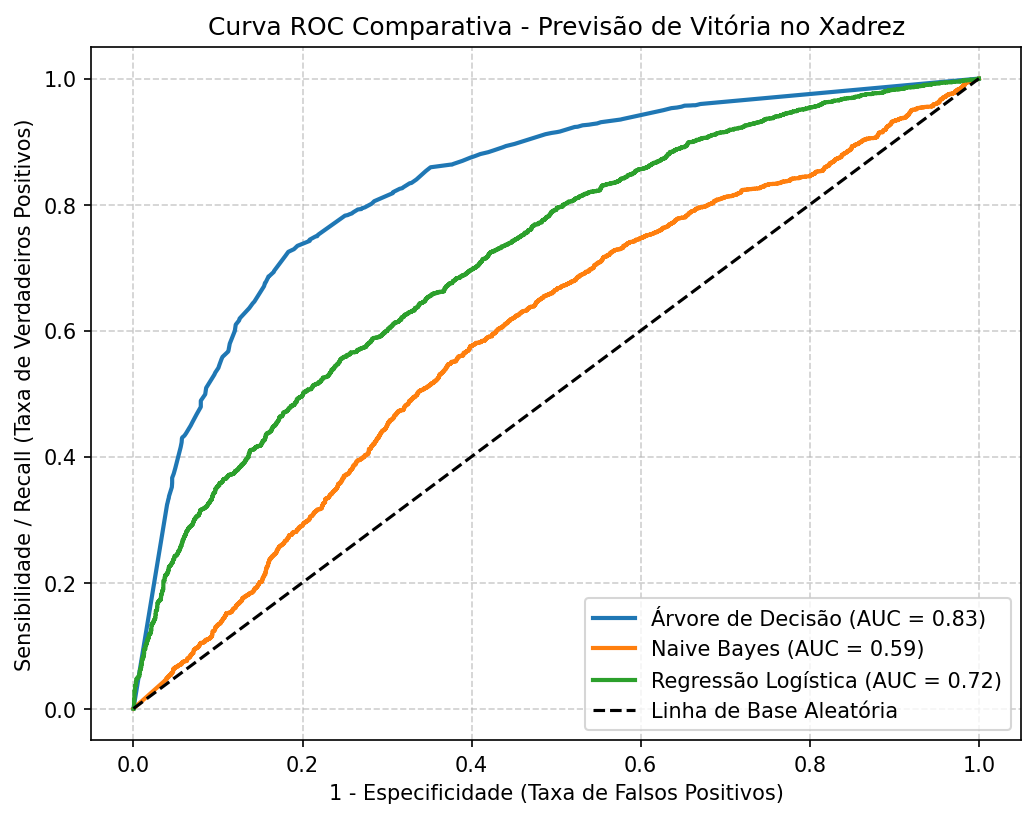

In [20]:
import matplotlib.pyplot as plt

plt.figure(figsize=(8, 6), dpi=150)

for name, res in results.items():
    plt.plot(res['fpr'], res['tpr'], label=f"{name} (AUC = {res['auc']:.2f})", linewidth=2)

plt.plot([0, 1], [0, 1], 'k--', label="Linha de Base Aleatória")
plt.grid(True, linestyle="--", alpha=0.6)
plt.title("Curva ROC Comparativa - Previsão de Vitória no Xadrez", fontsize=12)
plt.xlabel("1 - Especificidade (Taxa de Falsos Positivos)", fontsize=10)
plt.ylabel("Sensibilidade / Recall (Taxa de Verdadeiros Positivos)", fontsize=10)
plt.legend(loc="lower right")
plt.show()

## 5. Exportação das matrizes de confusão para o Excel

In [21]:
import openpyxl

# Exportando as Matrizes de Confusão para o Excel
wb = openpyxl.Workbook()
wb.remove(wb.active) # Remove a aba padrão

for name, model in models.items():
    pred = model.predict(X_test)
    cm = metrics.confusion_matrix(y_test, pred)
    
    cm_df = pd.DataFrame(
        cm,
        index=['Real: Derrota (Black)', 'Real: Vitória (White)'],
        columns=['Previsto: Derrota (Black)', 'Previsto: Vitória (White)']
    )
    
    ws = wb.create_sheet(title=name)
    ws.append([f"Matriz de Confusão - {name}"])
    ws.append([])
    ws.append([""] + list(cm_df.columns))
    
    for idx, row in cm_df.iterrows():
        ws.append([idx] + list(row.values))

wb.save("./apresentação/matrizes_confusao_xadrez.xlsx")
print("Matrizes de confusão exportadas para Excel com sucesso!")

Matrizes de confusão exportadas para Excel com sucesso!
